In [1]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
from torchvision.models.detection import ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights
from torchvision.models.detection import retinanet_resnet50_fpn, RetinaNet_ResNet50_FPN_Weights

torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [2]:
img = cv2.cvtColor(cv2.imread('bus.jpg'), cv2.COLOR_BGR2RGB)
conf = 0.4
img.shape

(1080, 810, 3)

In [3]:
yolo = YOLO('yolov3u.pt')
ssd_w = SSDLite320_MobileNet_V3_Large_Weights.DEFAULT
ssd = ssdlite320_mobilenet_v3_large(weights=ssd_w).eval()
retina_w = RetinaNet_ResNet50_FPN_Weights.DEFAULT
retina = retinanet_resnet50_fpn(weights=retina_w).eval()


def run_yolo(rgb):
    r = yolo(rgb[:, :, ::-1], conf=conf, verbose=False)[0]
    return [(yolo.names[int(b.cls[0])], float(b.conf[0]), b.xyxy[0].tolist()) for b in r.boxes]


def run_tv(model, names):
    def run(rgb):
        t = torch.from_numpy(rgb).permute(2, 0, 1).float() / 255
        o = model([t])[0]
        return [(names[int(l)], float(s), b.tolist()) for b, l, s in zip(o['boxes'], o['labels'], o['scores']) if s >= conf]
    return run


models = {
    'YOLOv3': (run_yolo, yolo.model),
    'SSD': (run_tv(ssd, ssd_w.meta['categories']), ssd),
    'RetinaNet': (run_tv(retina, retina_w.meta['categories']), retina),
}

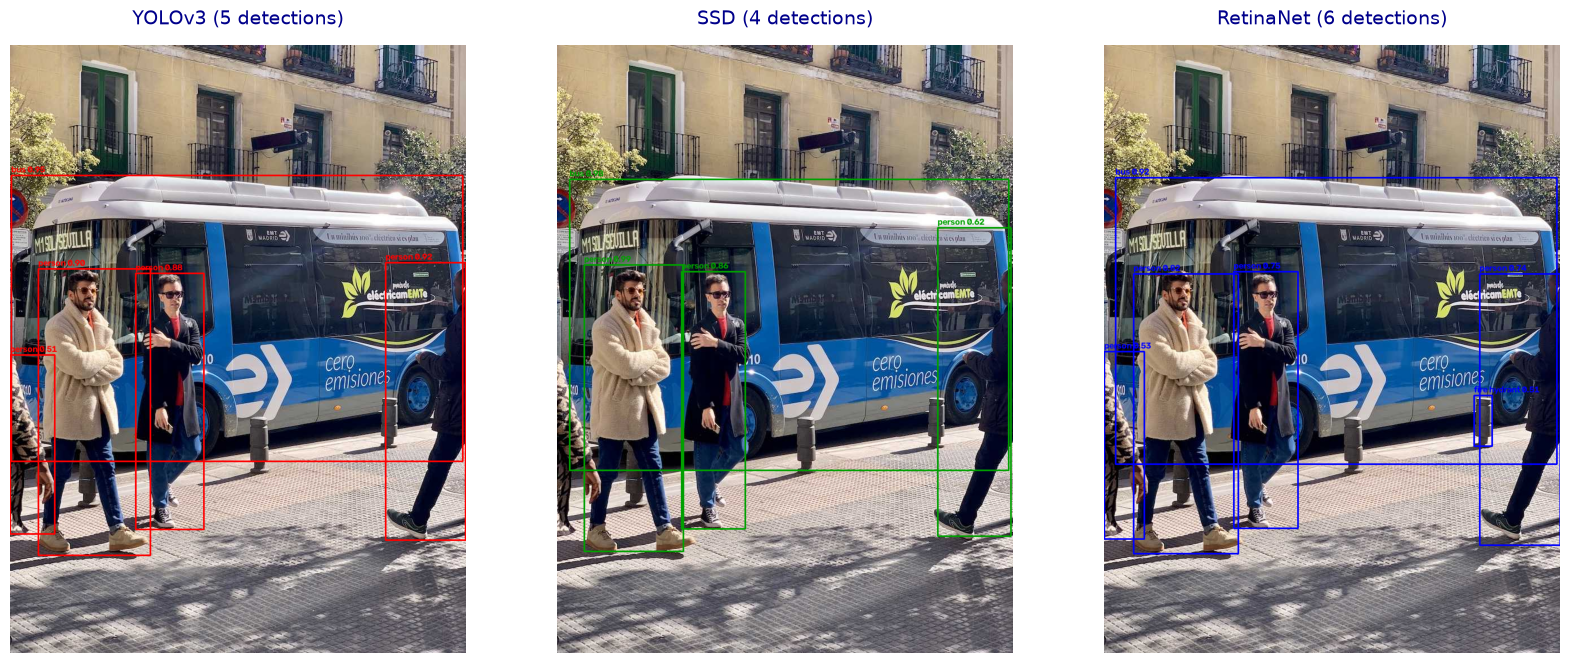

In [4]:
colors = {'YOLOv3': (255, 0, 0), 'SSD': (0, 160, 0), 'RetinaNet': (0, 0, 255)}
found = {}
panels = []

for name, (run, _) in models.items():
    found[name] = run(img)
    out = img.copy()
    for label, score, (x1, y1, x2, y2) in found[name]:
        cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), colors[name], 2)
        cv2.putText(out, f'{label} {score:.2f}', (int(x1), int(y1) - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, colors[name], 2)
    panels.append((f'{name} ({len(found[name])} detections)', out))

fig, axes = plt.subplots(1, 3, figsize=(20, 8))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

plt.show()

In [5]:
rows = []
for name, (run, net) in models.items():
    for _ in range(3):
        run(img)
    times = []
    for _ in range(15):
        start = time.perf_counter()
        run(img)
        times.append(time.perf_counter() - start)

    ms = np.mean(times) * 1000
    dets = found[name]
    rows.append({
        'model': name,
        'size_mb': sum(p.numel() for p in net.parameters()) * 4 / 1e6,
        'ms_per_frame': ms,
        'fps': 1000 / ms,
        'detections': len(dets),
        'mean_conf': np.mean([d[1] for d in dets]),
        'small': sum((d[2][2] - d[2][0]) * (d[2][3] - d[2][1]) < 64 * 64 for d in dets),
    })

table = pd.DataFrame(rows).set_index('model').round(2)
table

,size_mb,ms_per_frame,fps,detections,mean_conf,small
model,,,,,,
YOLOv3,415.02,3839.23,0.26,5,0.83,0
SSD,13.76,355.42,2.81,4,0.87,0
RetinaNet,136.06,7539.28,0.13,6,0.71,1


In [6]:
per_class = pd.DataFrame([(m, d[0], d[1]) for m, ds in found.items() for d in ds], columns=['model', 'class', 'conf'])
per_class.groupby(['class', 'model'])['conf'].agg(['count', 'mean']).round(2).unstack('model')

count                  mean             
model        RetinaNet  SSD YOLOv3 RetinaNet   SSD YOLOv3
class                                                    
bus                1.0  1.0    1.0      0.92  0.98   0.95
fire hydrant       1.0  NaN    NaN      0.51   NaN    NaN
person             4.0  3.0    4.0      0.71  0.83   0.80

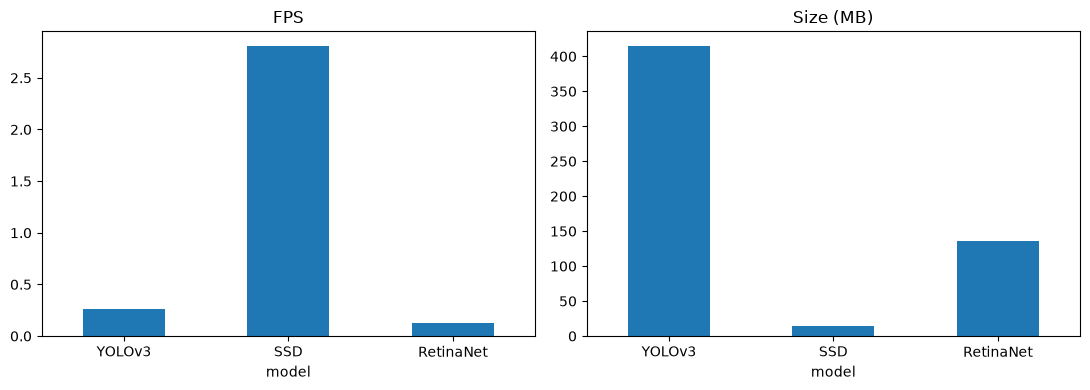

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
table['fps'].plot.bar(ax=axes[0], rot=0, title='FPS')
table['size_mb'].plot.bar(ax=axes[1], rot=0, title='Size (MB)')
plt.tight_layout()
plt.show()
os.makedirs('output', exist_ok=True)
fig.savefig('output/task2_compare.png')

In [8]:
webcam = False
name = 'SSD'

if webcam:
    cap = cv2.VideoCapture(0)
    cap.set(3, 640)
    cap.set(4, 480)

    while True:
        success, frame = cap.read()
        start = time.perf_counter()
        dets = models[name][0](cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        fps = 1 / (time.perf_counter() - start)
        for label, score, (x1, y1, x2, y2) in dets:
            cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
            cv2.putText(frame, f'{label} {score:.2f}', (int(x1), int(y1) - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
        cv2.putText(frame, f'{name} {fps:.1f} FPS', (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        cv2.imshow('Webcam', frame)
        if cv2.waitKey(1) == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

All three are pretrained COCO models run on the same image on cpu with a 0.4 confidence threshold. YOLOv3 is 415 MB (fp32) and takes 3839 ms per frame (0.26 FPS), SSD with MobileNetV3 is 13.8 MB and takes 355 ms (2.8 FPS), RetinaNet with ResNet50 is 136 MB and takes 7539 ms (0.13 FPS). Mean confidence is 0.83, 0.87 and 0.71.

Real time: SSD is the only one close on cpu, about 10x faster than YOLOv3. YOLOv3 would be fine on a gpu, and yolov8n from task 1 is much faster than v3.

Small objects: RetinaNet found the most, including the small bollard on the right (the only detection under 64x64), but it labelled it fire hydrant at 0.51 which is wrong. SSD works on 320x320 input and missed one of the four people. YOLOv3 found all four people.

Cpu only: SSD, it is 13.8 MB and the only one that runs at a usable speed. YOLOv3 and RetinaNet are too heavy without a gpu.

Confidence scores are not comparable across models (RetinaNet is lower because of focal loss) and this is one image, so this is only a rough comparison. A labelled set and mAP would be needed to say which is more accurate.